In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../outputs/ipl_t20i_regular_deliveries.csv")

print("Dataset shape:", df.shape)
print(df.columns.tolist())


Dataset shape: (193988, 69)
['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'batting_team_id', 'bowling_team_id', 'striker_id', 'striker_name', 'non_striker_id', 'non_striker_name', 'bowler_id', 'bowler_name', 'batting_type', 'bowling_type', 'batting_order', 'runs', 'is_four', 'is_six', 'is_wicket', 'dismissal_type_id', 'dismissal_type', 'dismissed_player_id', 'extras_type', 'extras1_runs', 'extras_2_runs', 'pace_or_spin', 'bowl_speed', 'stroke', 'delivery_style', 'over_or_around', 'on_or_off', 'delivery_ist_time', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_win_team_id', 'toss_opted', 'man_of_the_match', 'first_inn_revised_overs', 'second_inn_revised_overs', 'revised_target', 'knock_out', 'win_team_id', 'result', 'comp_name', 'match_format', 'season', 'batter_runs', 'extras_runs', 'total_runs', 'ball_status', 'is_lega

C:\Users\param\AppData\Local\Temp\ipykernel_31636\255308280.py:6: DtypeWarning: Columns (56) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../outputs/ipl_t20i_regular_deliveries.csv")


In [2]:

# ==========================================
# CELL 1: MATCH STATE BEFORE EACH DELIVERY
# EXCLUDING REVISED / SHORTENED MATCHES
# ==========================================

# Work on a fresh copy of the original dataset
df = df.copy()

# Convert revised-match fields to numeric
revision_cols = [
    "revised_target",
    "first_inn_revised_overs",
    "second_inn_revised_overs"
]

for col in revision_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Identify matches affected by revised targets or overs
match_revision = (
    df.groupby("match_id")[revision_cols]
    .first()
)

revised_match_ids = match_revision[
    match_revision.notna().any(axis=1)
].index

print("Total matches:", df["match_id"].nunique())
print("Revised/shortened matches excluded:", len(revised_match_ids))

# Keep only standard matches
df_regular = df[
    ~df["match_id"].isin(revised_match_ids)
].copy()

# Sort deliveries chronologically
df_regular = df_regular.sort_values(
    ["match_id", "innings", "innings_ball_num"]
).copy()

# Ensure numeric columns
numeric_cols = [
    "total_runs",
    "cumulative_runs",
    "cumulative_wickets",
    "legal_balls_bowled"
]

for col in numeric_cols:
    df_regular[col] = pd.to_numeric(
        df_regular[col], errors="coerce"
    ).fillna(0)

# Match state BEFORE each delivery
groups = df_regular.groupby(
    ["match_id", "innings"],
    sort=False
)

df_regular["runs_before"] = (
    groups["cumulative_runs"].shift(1).fillna(0)
)

df_regular["wickets_before"] = (
    groups["cumulative_wickets"].shift(1).fillna(0)
)

df_regular["legal_balls_before"] = (
    groups["legal_balls_bowled"].shift(1).fillna(0)
)

# Calculate first innings total
first_innings = (
    df_regular[df_regular["innings"] == 1]
    .groupby("match_id")["total_runs"]
    .sum()
    .rename("first_innings_score")
)

# Attach first innings total to each delivery
df_regular = df_regular.drop(
    columns=["first_innings_score"],
    errors="ignore"
)

# Attach first innings total
df_regular = df_regular.join(
    first_innings,
    on="match_id"
)
# Select second innings
chase = df_regular[
    df_regular["innings"] == 2
].copy()

# Calculate target
chase["target"] = chase["first_innings_score"] + 1

# Runs required before each delivery
chase["runs_required"] = (
    chase["target"] - chase["runs_before"]
).clip(lower=0)

# Balls remaining in a standard 20-over innings
chase["balls_remaining"] = (
    120 - chase["legal_balls_before"]
).clip(lower=0)

# Wickets remaining
chase["wickets_remaining"] = (
    10 - chase["wickets_before"]
).clip(lower=0)

# Required run rate
chase["required_run_rate"] = np.where(
    chase["balls_remaining"] > 0,
    chase["runs_required"] * 6 /
    chase["balls_remaining"],
    np.nan
)

# Exclude completed chases and all-out innings
chase = chase[
    (chase["runs_required"] > 0) &
    (chase["balls_remaining"] > 0) &
    (chase["wickets_remaining"] > 0)
].copy()

# Summary
print("\nSTANDARD-MATCH CHASE DATASET")
print("--------------------------------")
print("Dataset shape:", chase.shape)
print("Unique matches:", chase["match_id"].nunique())

display(
    chase[
        [
            "match_id",
            "striker_name",
            "runs_required",
            "balls_remaining",
            "wickets_remaining",
            "required_run_rate"
        ]
    ].head(10).round(2)
)

Total matches: 837
Revised/shortened matches excluded: 34

STANDARD-MATCH CHASE DATASET
--------------------------------
Dataset shape: (90116, 77)
Unique matches: 790


,match_id,striker_name,runs_required,balls_remaining,wickets_remaining,required_run_rate
121,13511,Brandon King,104.0,120.0,10.0,5.20
122,13511,Brandon King,104.0,119.0,10.0,5.24
123,13511,Brandon King,100.0,118.0,10.0,5.08
124,13511,Brandon King,100.0,117.0,10.0,5.13
125,13511,Brandon King,100.0,116.0,10.0,5.17
126,13511,Shai Hope,99.0,115.0,10.0,5.17
127,13511,Shai Hope,98.0,114.0,10.0,5.16
128,13511,Shai Hope,94.0,113.0,10.0,4.99
129,13511,Brandon King,93.0,112.0,10.0,4.98
130,13511,Brandon King,93.0,111.0,10.0,5.03


In [3]:

# ==========================================
# CELL 2: PRESSURE INDEX
# ==========================================

# Pressure components
chase["rrr_pressure"] = (
    chase["required_run_rate"].clip(0, 15) / 15
)

chase["wicket_pressure"] = (
    chase["wickets_before"] / 9
).clip(0, 1)

chase["stage_pressure"] = (
    chase["legal_balls_before"] / 120
).clip(0, 1)

# Weighted pressure score
chase["pressure_score"] = 100 * (
    0.50 * chase["rrr_pressure"] +
    0.30 * chase["wicket_pressure"] +
    0.20 * chase["stage_pressure"]
)

# Classify pressure deliveries
chase["is_pressure"] = (
    chase["pressure_score"] >= 60
)

# Summary
print("PRESSURE CLASSIFICATION")
print("-----------------------")

print(
    chase["is_pressure"]
    .value_counts()
    .rename(index={
        True: "Pressure",
        False: "Normal"
    })
)

print("\nPressure percentage:")
print(
    round(chase["is_pressure"].mean() * 100, 2),
    "%"
)

display(
    chase[
        [
            "match_id",
            "striker_name",
            "runs_required",
            "balls_remaining",
            "wickets_remaining",
            "required_run_rate",
            "pressure_score",
            "is_pressure"
        ]
    ].head(10).round(2)
)


PRESSURE CLASSIFICATION
-----------------------
is_pressure
Normal      64567
Pressure    25549
Name: count, dtype: int64

Pressure percentage:
28.35 %


,match_id,striker_name,runs_required,balls_remaining,wickets_remaining,required_run_rate,pressure_score,is_pressure
121,13511,Brandon King,104.0,120.0,10.0,5.20,17.33,False
122,13511,Brandon King,104.0,119.0,10.0,5.24,17.65,False
123,13511,Brandon King,100.0,118.0,10.0,5.08,17.28,False
124,13511,Brandon King,100.0,117.0,10.0,5.13,17.59,False
125,13511,Brandon King,100.0,116.0,10.0,5.17,17.91,False
126,13511,Shai Hope,99.0,115.0,10.0,5.17,18.05,False
127,13511,Shai Hope,98.0,114.0,10.0,5.16,18.19,False
128,13511,Shai Hope,94.0,113.0,10.0,4.99,17.80,False
129,13511,Brandon King,93.0,112.0,10.0,4.98,17.94,False
130,13511,Brandon King,93.0,111.0,10.0,5.03,18.26,False


In [4]:
# ==========================================
# VERIFY REVISED TARGETS AND OVERS
# ==========================================

# Total runs and legal balls for each innings
innings_summary = (
    df.groupby(["match_id", "innings"])
    .agg(
        innings_score=("total_runs", "sum"),
        legal_balls=("is_legal_ball", "sum")
    )
    .reset_index()
)

# Separate first and second innings
first_innings = (
    innings_summary[innings_summary["innings"] == 1]
    [["match_id", "innings_score", "legal_balls"]]
    .rename(columns={
        "innings_score": "first_innings_score",
        "legal_balls": "first_innings_legal_balls"
    })
)

second_innings = (
    innings_summary[innings_summary["innings"] == 2]
    [["match_id", "legal_balls"]]
    .rename(columns={
        "legal_balls": "second_innings_legal_balls"
    })
)

# Match-level metadata
match_check = (
    df.groupby("match_id")
    .agg(
        revised_target=("revised_target", "first"),
        first_inn_revised_overs=("first_inn_revised_overs", "first"),
        second_inn_revised_overs=("second_inn_revised_overs", "first"),
        comp_name=("comp_name", "first")
    )
    .reset_index()
)

match_check = (
    match_check
    .merge(first_innings, on="match_id", how="left")
    .merge(second_innings, on="match_id", how="left")
)

# Display matches with any revised match information
revised_matches = match_check[
    match_check[
        [
            "revised_target",
            "first_inn_revised_overs",
            "second_inn_revised_overs"
        ]
    ].notna().any(axis=1)
].copy()

# Compact revised-match diagnostic
revised_matches["first_overs_actual"] = (
    revised_matches["first_innings_legal_balls"] / 6
)

revised_matches["second_overs_actual"] = (
    revised_matches["second_innings_legal_balls"] / 6
)

display(
    revised_matches[
        [
            "match_id",
            "comp_name",
            "first_innings_score",
            "revised_target",
            "first_inn_revised_overs",
            "second_inn_revised_overs",
            "first_overs_actual",
            "second_overs_actual"
        ]
    ]
    .round(2)
    .sort_values("match_id")
    .reset_index(drop=True)
)

,match_id,comp_name,first_innings_score,revised_target,first_inn_revised_overs,second_inn_revised_overs,first_overs_actual,second_overs_actual
0,13612,Sri Lanka in Australia T20I Series 2022,149,143.0,NaN,114.0,20.00,19.00
1,15410,South Africa in India T20I Series 2022,28,NaN,114.0,NaN,3.50,NaN
2,15546,Bangladesh in West Indies T20I Series 2022,105,NaN,84.0,NaN,13.17,NaN
3,16753,Afghanistan in Ireland T20I Series 2022,132,NaN,66.0,NaN,11.00,10.83
4,16754,Afghanistan in Ireland T20I Series 2022,95,56.0,NaN,42.0,15.00,6.67
5,17395,Australia in India T20I Series 2022,90,91.0,48.0,48.0,8.00,7.33
6,17765,England in Australia T20I Series 2022,112,130.0,72.0,72.0,12.00,3.83
7,19959,West Indies in South Africa T20I Series 2023,131,NaN,66.0,NaN,11.00,10.50
8,21070,Ireland in Bangladesh T20I Series 2023,207,104.0,NaN,48.0,19.33,8.00
9,21071,Ireland in Bangladesh T20I Series 2023,202,203.0,102.0,102.0,17.00,17.00


Pressure delivery distribution:
is_pressure
False    64567
True     25549
Name: count, dtype: int64

Pressure score summary:


,count,mean,std,min,25%,50%,75%,max
is_pressure,,,,,,,,
False,64567.0,40.555389,10.130685,5.391386,33.037522,40.485507,48.203274,59.994253
True,25549.0,76.982591,11.341899,60.000000,66.833333,75.814815,86.500000,99.833333


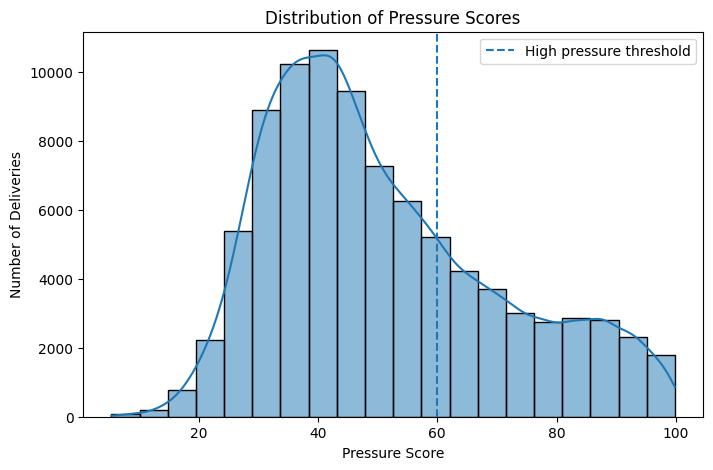

In [5]:

# ==========================================
# CELL 2: PRESSURE INDEX
# ==========================================

# Normalize required run rate between 0 and 1
chase["rrr_pressure"] = (
    chase["required_run_rate"].clip(0, 15) / 15
).fillna(1)

# More wickets lost = more pressure
chase["wicket_pressure"] = (
    chase["wickets_before"] / 9
).clip(0, 1)

# Later innings stage = more pressure
chase["stage_pressure"] = (
    chase["legal_balls_before"] / 120
).clip(0, 1)

# Composite pressure score between 0 and 100
chase["pressure_score"] = 100 * (
    0.50 * chase["rrr_pressure"] +
    0.30 * chase["wicket_pressure"] +
    0.20 * chase["stage_pressure"]
)

# High pressure threshold
chase["is_pressure"] = (
    chase["pressure_score"] >= 60
)

print("Pressure delivery distribution:")
print(chase["is_pressure"].value_counts())

print("\nPressure score summary:")
display(
    chase.groupby("is_pressure")["pressure_score"].describe()
)

# Visualize pressure distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    chase["pressure_score"],
    bins=20,
    kde=True
)

plt.axvline(
    60,
    linestyle="--",
    label="High pressure threshold"
)

plt.title("Distribution of Pressure Scores")
plt.xlabel("Pressure Score")
plt.ylabel("Number of Deliveries")
plt.legend()
plt.show()


#### Batting analytics
We will compare each batter's strike rate in high-pressure deliveries with their strike rate in other chase deliveries.

In [6]:

# ==========================================
# CELL 3: BATTING ANALYTICS
# ==========================================

batting = chase[
    chase["striker_name"].notna() &
    chase["striker_id"].notna()
].copy()

# A wide does not count as a ball faced.
# A no-ball counts as a ball faced.
# Penalty event is excluded.
batting["batter_ball"] = ~batting["extras_type"].isin(
    ["wide", "Penalty"]
)

# Ensure boundary indicators are numeric
batting["is_four"] = pd.to_numeric(
    batting["is_four"], errors="coerce"
).fillna(0)

batting["is_six"] = pd.to_numeric(
    batting["is_six"], errors="coerce"
).fillna(0)

# Count only dismissals of the striker
batting["batter_dismissal"] = (
    batting["is_wicket"].eq(1) &
    batting["dismissed_player_id"].eq(batting["striker_id"])
)

# Separate pressure and normal deliveries
batting["pressure_group"] = np.where(
    batting["is_pressure"],
    "Pressure",
    "Normal"
)

# Aggregate performance
batting_summary = (
    batting.groupby(
        ["striker_id", "striker_name", "pressure_group"]
    )
    .agg(
        runs=("batter_runs", "sum"),
        balls=("batter_ball", "sum"),
        fours=("is_four", "sum"),
        sixes=("is_six", "sum"),
        dismissals=("batter_dismissal", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

# Strike rate
batting_summary["strike_rate"] = (
    batting_summary["runs"] /
    batting_summary["balls"].replace(0, np.nan) * 100
)

# Boundary percentage
batting_summary["boundary_percentage"] = (
    (batting_summary["fours"] + batting_summary["sixes"]) /
    batting_summary["balls"].replace(0, np.nan) * 100
)

display(
    batting_summary.sort_values(
        ["pressure_group", "runs"],
        ascending=[True, False]
    ).head(20)
)


,striker_id,striker_name,pressure_group,runs,balls,fours,sixes,dismissals,matches,strike_rate,boundary_percentage
575,6281,Abhishek Sharma,Normal,1831,986,181,116,54,61,185.699797,30.121704
580,6288,Shubman Gill,Normal,1787,1259,191,59,47,57,141.938046,19.857029
142,1699,Suryakumar Yadav,Normal,1738,1064,180,84,34,61,163.345865,24.812030
5,47,Virat Kohli,Normal,1605,1067,166,56,26,39,150.421743,20.805998
666,6819,Yashasvi Jaiswal,Normal,1577,989,185,67,35,42,159.453994,25.480283
394,4117,Ishan Kishan,Normal,1525,1085,164,69,51,58,140.552995,21.474654
77,813,Jos Buttler,Normal,1445,936,156,64,42,55,154.380342,23.504274
79,818,Mitchell Marsh,Normal,1391,891,130,84,38,48,156.116723,24.017957
672,6931,Pathum Nissanka,Normal,1390,949,143,49,29,38,146.469968,20.231823
526,5553,Phil Salt,Normal,1320,772,154,61,29,36,170.984456,27.849741


In [7]:

# ==========================================
# CELL 4: BATTING PRESSURE RANKINGS
# ==========================================

# Pivot pressure and normal performance
batting_pivot = batting_summary.pivot(
    index=["striker_id", "striker_name"],
    columns="pressure_group",
    values=[
        "runs", "balls", "strike_rate",
        "boundary_percentage", "dismissals", "matches"
    ]
)

batting_pivot.columns = [
    f"{metric}_{group.lower()}"
    for metric, group in batting_pivot.columns
]

batting_pivot = batting_pivot.reset_index()

# Ensure both groups exist
required_cols = [
    "runs_pressure", "balls_pressure",
    "strike_rate_pressure", "boundary_percentage_pressure",
    "dismissals_pressure", "matches_pressure",
    "runs_normal", "balls_normal",
    "strike_rate_normal", "boundary_percentage_normal",
    "dismissals_normal", "matches_normal"
]

for col in required_cols:
    if col not in batting_pivot.columns:
        batting_pivot[col] = 0

# Minimum sample-size requirements
batting_pivot = batting_pivot[
    (batting_pivot["balls_pressure"] >= 30) &
    (batting_pivot["balls_normal"] >= 30)
].copy()

# Difference between pressure and normal performance
batting_pivot["sr_improvement"] = (
    batting_pivot["strike_rate_pressure"] -
    batting_pivot["strike_rate_normal"]
)

# Standardize both indicators
def safe_zscore(series):
    std = series.std(ddof=0)
    if pd.isna(std) or std == 0:
        return pd.Series(0, index=series.index)
    return (series - series.mean()) / std

batting_pivot["z_pressure_sr"] = safe_zscore(
    batting_pivot["strike_rate_pressure"]
)

batting_pivot["z_sr_improvement"] = safe_zscore(
    batting_pivot["sr_improvement"]
)

# Composite score
batting_pivot["raw_batting_score"] = (
    0.50 * batting_pivot["z_pressure_sr"] +
    0.50 * batting_pivot["z_sr_improvement"]
)

# Sample-size reliability adjustment
K_BAT = 60

batting_pivot["reliability"] = (
    batting_pivot["balls_pressure"] /
    (batting_pivot["balls_pressure"] + K_BAT)
)

batting_pivot["batting_score"] = (
    batting_pivot["raw_batting_score"] *
    batting_pivot["reliability"]
)

# Final ranking
batting_rankings = (
    batting_pivot
    .sort_values("batting_score", ascending=False)
    .reset_index(drop=True)
)

batting_rankings.insert(
    0, "rank", range(1, len(batting_rankings) + 1)
)

batting_top10 = batting_rankings.head(10)

display(
    batting_top10[
        [
            "rank", "striker_name",
            "runs_pressure", "balls_pressure",
            "strike_rate_pressure", "strike_rate_normal",
            "sr_improvement", "reliability", "batting_score"
        ]
    ]
)

,rank,striker_name,runs_pressure,balls_pressure,strike_rate_pressure,strike_rate_normal,sr_improvement,reliability,batting_score
0,1,Jason Holder,332.0,210.0,158.095238,60.344828,97.750411,0.777778,1.064516
1,2,David Miller,770.0,431.0,178.654292,113.855422,64.798871,0.877800,1.007974
2,3,Dhruv Jurel,337.0,178.0,189.325843,126.119403,63.206440,0.747899,0.991936
3,4,Rinku Singh,428.0,232.0,184.482759,127.868852,56.613906,0.794521,0.880031
4,5,Naman Dhir,209.0,101.0,206.930693,158.163265,48.767428,0.627329,0.876565
5,6,Dasun Shanaka,381.0,226.0,168.584071,100.000000,68.584071,0.790210,0.808659
6,7,Namboori Tilak Varma,706.0,400.0,176.500000,121.404304,55.095696,0.869565,0.802957
7,8,Sanju Samson,184.0,92.0,200.000000,148.329049,51.670951,0.605263,0.797088
8,9,Shai Hope,97.0,49.0,197.959184,123.923445,74.035739,0.449541,0.763642
9,10,Gulbadin Naib,62.0,32.0,193.750000,92.063492,101.686508,0.347826,0.743607


#### Bowling analytics
For bowlers, we will compare economy rate and wicket-taking performance in pressure versus normal chase deliveries.

In [8]:

# ==========================================
# CELL 5: BOWLING ANALYTICS
# ==========================================

bowling = chase[
    chase["bowler_name"].notna() &
    chase["bowler_id"].notna()
].copy()

# Start with total runs
bowling["bowler_runs"] = bowling["total_runs"].copy()

# Remove extras not charged to the bowler
not_bowler_runs = ["byes", "legbyes", "Penalty"]

mask = bowling["extras_type"].isin(not_bowler_runs)

bowling.loc[mask, "bowler_runs"] = (
    bowling.loc[mask, "bowler_runs"] -
    bowling.loc[mask, "extras_runs"]
)

bowling["bowler_runs"] = bowling["bowler_runs"].clip(lower=0)

# Separate pressure and normal deliveries
bowling["pressure_group"] = np.where(
    bowling["is_pressure"],
    "Pressure",
    "Normal"
)

# Aggregate bowling performance
bowling_summary = (
    bowling.groupby(
        ["bowler_id", "bowler_name", "pressure_group"]
    )
    .agg(
        runs_conceded=("bowler_runs", "sum"),
        legal_balls=("is_legal_ball", "sum"),
        wickets=("is_bowler_wicket", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

# Economy rate
bowling_summary["economy"] = (
    bowling_summary["runs_conceded"] /
    bowling_summary["legal_balls"].replace(0, np.nan) * 6
)

# Wickets per 100 legal balls
bowling_summary["wickets_per_100_balls"] = (
    bowling_summary["wickets"] /
    bowling_summary["legal_balls"].replace(0, np.nan) * 100
)

display(bowling_summary.head(20))

,bowler_id,bowler_name,pressure_group,runs_conceded,legal_balls,wickets,matches,economy,wickets_per_100_balls
0,23,Piyush Chawla,Normal,198,159,7,10,7.471698,4.402516
1,23,Piyush Chawla,Pressure,99,57,2,4,10.421053,3.508772
2,28,Ishant Sharma,Normal,206,144,7,11,8.583333,4.861111
3,28,Ishant Sharma,Pressure,84,43,3,7,11.720930,6.976744
4,47,Virat Kohli,Pressure,6,6,0,1,6.000000,0.000000
5,143,Dinesh Karthik,Pressure,18,6,0,1,18.000000,0.000000
6,147,Pradeep Sangwan,Normal,23,12,0,1,11.500000,0.000000
7,152,Ravindra Jadeja,Normal,696,547,17,37,7.634369,3.107861
8,152,Ravindra Jadeja,Pressure,312,208,15,20,9.000000,7.211538
9,158,Amit Mishra,Normal,35,24,1,2,8.750000,4.166667


In [9]:

# ==========================================
# CELL 6: BOWLING PRESSURE RANKINGS
# ==========================================

bowling_pivot = bowling_summary.pivot(
    index=["bowler_id", "bowler_name"],
    columns="pressure_group",
    values=[
        "runs_conceded", "legal_balls",
        "wickets", "economy",
        "wickets_per_100_balls", "matches"
    ]
)

bowling_pivot.columns = [
    f"{metric}_{group.lower()}"
    for metric, group in bowling_pivot.columns
]

bowling_pivot = bowling_pivot.reset_index()

required_cols = [
    "runs_conceded_pressure", "legal_balls_pressure",
    "wickets_pressure", "economy_pressure",
    "wickets_per_100_balls_pressure", "matches_pressure",
    "runs_conceded_normal", "legal_balls_normal",
    "wickets_normal", "economy_normal",
    "wickets_per_100_balls_normal", "matches_normal"
]

for col in required_cols:
    if col not in bowling_pivot.columns:
        bowling_pivot[col] = 0

# Minimum sample requirements
bowling_pivot = bowling_pivot[
    (bowling_pivot["legal_balls_pressure"] >= 60) &
    (bowling_pivot["legal_balls_normal"] >= 30)
].copy()

# Improvement in economy: positive means better under pressure
bowling_pivot["economy_improvement"] = (
    bowling_pivot["economy_normal"] -
    bowling_pivot["economy_pressure"]
)

# Improvement in wicket-taking rate
bowling_pivot["wicket_improvement"] = (
    bowling_pivot["wickets_per_100_balls_pressure"] -
    bowling_pivot["wickets_per_100_balls_normal"]
)

# Standardize indicators
bowling_pivot["z_economy_improvement"] = safe_zscore(
    bowling_pivot["economy_improvement"]
)

bowling_pivot["z_wicket_improvement"] = safe_zscore(
    bowling_pivot["wicket_improvement"]
)

# Composite score
bowling_pivot["raw_bowling_score"] = (
    0.50 * bowling_pivot["z_economy_improvement"] +
    0.50 * bowling_pivot["z_wicket_improvement"]
)

# Sample-size reliability adjustment
K_BOWL = 60

bowling_pivot["reliability"] = (
    bowling_pivot["legal_balls_pressure"] /
    (bowling_pivot["legal_balls_pressure"] + K_BOWL)
)

bowling_pivot["bowling_score"] = (
    bowling_pivot["raw_bowling_score"] *
    bowling_pivot["reliability"]
)

# Final ranking
bowling_rankings = (
    bowling_pivot
    .sort_values("bowling_score", ascending=False)
    .reset_index(drop=True)
)

bowling_rankings.insert(
    0, "rank", range(1, len(bowling_rankings) + 1)
)

bowling_top10 = bowling_rankings.head(10)

display(
    bowling_top10[
        [
            "rank", "bowler_name",
            "legal_balls_pressure",
            "economy_pressure", "economy_normal",
            "economy_improvement",
            "wickets_per_100_balls_pressure",
            "wicket_improvement",
            "reliability", "bowling_score"
        ]
    ]
)

,rank,bowler_name,legal_balls_pressure,economy_pressure,economy_normal,economy_improvement,wickets_per_100_balls_pressure,wicket_improvement,reliability,bowling_score
0,1,Gerald Coetzee,63.0,6.571429,10.156425,3.584996,14.285714,9.816441,0.512195,1.311615
1,2,Jamie Overton,86.0,7.465116,10.545455,3.080338,10.465116,7.434813,0.589041,1.148875
2,3,Mohit Sharma,157.0,8.331210,9.709091,1.377881,12.101911,8.465547,0.723502,1.128844
3,4,Akeal Hosein,94.0,6.191489,8.291845,2.100356,12.765957,8.044927,0.610390,1.055313
4,5,Umran Malik,82.0,8.560976,10.512000,1.951024,13.414634,7.814634,0.577465,0.944532
5,6,Nitish Reddy,145.0,7.862069,10.260355,2.398286,8.275862,5.317282,0.707317,0.939495
6,7,Eshan Malinga,154.0,8.493506,10.523364,2.029858,10.389610,5.716713,0.719626,0.918448
7,8,Rasikh Salam,117.0,10.000000,10.231579,0.231579,10.256410,9.203779,0.661017,0.863078
8,9,Mohammed Shami,70.0,7.542857,8.696907,1.154050,12.857143,8.527246,0.538462,0.805195
9,10,Shadab Khan,141.0,6.808511,7.636364,0.827853,9.929078,7.107761,0.701493,0.787723


In [10]:

# ==========================================
# CELL 7: RAJASTHAN ROYALS ANALYSIS
# ==========================================

RR_TEAM_ID = 3

# RR batters: RR was the batting team
rr_batting = batting[
    batting["batting_team_id"] == RR_TEAM_ID
].copy()

rr_batting_summary = (
    rr_batting.groupby(
        ["striker_id", "striker_name", "pressure_group"]
    )
    .agg(
        runs=("batter_runs", "sum"),
        balls=("batter_ball", "sum"),
        dismissals=("batter_dismissal", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

rr_batting_summary["strike_rate"] = (
    rr_batting_summary["runs"] /
    rr_batting_summary["balls"].replace(0, np.nan) * 100
)

# RR bowlers: RR was the bowling team
rr_bowling = bowling[
    bowling["bowling_team_id"] == RR_TEAM_ID
].copy()

rr_bowling_summary = (
    rr_bowling.groupby(
        ["bowler_id", "bowler_name", "pressure_group"]
    )
    .agg(
        runs_conceded=("bowler_runs", "sum"),
        legal_balls=("is_legal_ball", "sum"),
        wickets=("is_bowler_wicket", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

rr_bowling_summary["economy"] = (
    rr_bowling_summary["runs_conceded"] /
    rr_bowling_summary["legal_balls"].replace(0, np.nan) * 6
)

rr_bowling_summary["wickets_per_100_balls"] = (
    rr_bowling_summary["wickets"] /
    rr_bowling_summary["legal_balls"].replace(0, np.nan) * 100
)

print("Rajasthan Royals batting analysis:")
display(rr_batting_summary)

print("Rajasthan Royals bowling analysis:")
display(rr_bowling_summary)


Rajasthan Royals batting analysis:


,striker_id,striker_name,pressure_group,runs,balls,dismissals,matches,strike_rate
0,152,Ravindra Jadeja,Normal,43,35,0,3,122.857143
1,152,Ravindra Jadeja,Pressure,64,47,2,2,136.170213
2,305,Ravichandran Ashwin,Normal,46,47,4,6,97.872340
3,305,Ravichandran Ashwin,Pressure,55,34,4,8,161.764706
4,813,Jos Buttler,Normal,482,330,15,18,146.060606
5,813,Jos Buttler,Pressure,77,38,0,1,202.631579
6,1612,Yuzvendra Chahal,Pressure,5,8,1,1,62.500000
7,1944,Keshav Maharaj,Pressure,1,2,1,1,50.000000
8,2258,Sanju Samson,Normal,600,424,16,26,141.509434
9,2258,Sanju Samson,Pressure,184,92,5,6,200.000000


Rajasthan Royals bowling analysis:


,bowler_id,bowler_name,pressure_group,runs_conceded,legal_balls,wickets,matches,economy,wickets_per_100_balls
0,152,Ravindra Jadeja,Normal,132,89,4,7,8.898876,4.494382
1,152,Ravindra Jadeja,Pressure,47,31,2,3,9.096774,6.451613
2,305,Ravichandran Ashwin,Normal,519,414,15,24,7.521739,3.623188
3,305,Ravichandran Ashwin,Pressure,213,156,7,18,8.192308,4.487179
4,820,Nathan Coulter Nile,Pressure,48,19,0,1,15.157895,0.000000
...,...,...,...,...,...,...,...,...,...
60,20693,Kuldip Yadav,Pressure,38,18,2,2,12.666667,11.111111
61,41503,Yash Punja,Normal,80,55,0,4,8.727273,0.000000
62,41503,Yash Punja,Pressure,86,53,4,3,9.735849,7.547170
63,67036,Brijesh Sharma,Normal,177,99,5,8,10.727273,5.050505


,match_format,is_pressure,deliveries,matches
0,T20,False,29520,358
1,T20,True,12053,245
2,T20I,False,35047,432
3,T20I,True,13496,290


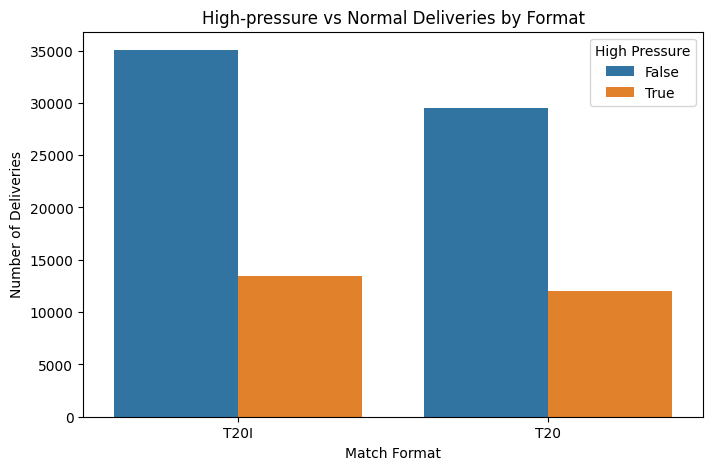

In [11]:

# ==========================================
# CELL 8: IPL VS T20I VALIDATION
# ==========================================

competition_pressure = (
    chase.groupby(["match_format", "is_pressure"])
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

display(competition_pressure)

# Pressure deliveries by competition format
plt.figure(figsize=(8, 5))

sns.countplot(
    data=chase,
    x="match_format",
    hue="is_pressure"
)

plt.title("High-pressure vs Normal Deliveries by Format")
plt.xlabel("Match Format")
plt.ylabel("Number of Deliveries")
plt.legend(title="High Pressure")
plt.show()


In [12]:

# ==========================================
# CELL 9: SAVE PROJECT OUTPUTS
# ==========================================

import os

os.makedirs("../outputs", exist_ok=True)

# Overall rankings
batting_rankings.to_csv(
    "../outputs/batting_pressure_rankings.csv",
    index=False
)

bowling_rankings.to_csv(
    "../outputs/bowling_pressure_rankings.csv",
    index=False
)

# Top 10 rankings
batting_top10.to_csv(
    "../outputs/top10_batters.csv",
    index=False
)

bowling_top10.to_csv(
    "../outputs/top10_bowlers.csv",
    index=False
)

# RR supplementary analysis
rr_batting_summary.to_csv(
    "../outputs/rr_batting_analysis.csv",
    index=False
)

rr_bowling_summary.to_csv(
    "../outputs/rr_bowling_analysis.csv",
    index=False
)

# Pressure dataset
chase.to_csv(
    "../outputs/chase_pressure_dataset.csv",
    index=False
)

# Competition validation
competition_pressure.to_csv(
    "../outputs/competition_pressure_validation.csv",
    index=False
)

print("All analytics outputs saved successfully!")


All analytics outputs saved successfully!


In [13]:
# Check which competitions are included in the T20 category

t20_competitions = (
    df_regular[df_regular["match_format"] == "T20"]
    [["comp_id", "comp_name"]]
    .drop_duplicates()
    .sort_values("comp_name")
)

display(t20_competitions.to_string(index=False))

' comp_id comp_name\n    1358  IPL 2022\n    1715  IPL 2023\n    2193  IPL 2024\n    2725  IPL 2025\n    3298  IPL 2026'

In [14]:
# ==========================================
# SAMPLE SIZE SENSITIVITY: BATTING
# ==========================================

# Compare rankings at different minimum pressure-ball thresholds
for minimum_balls in [30, 60, 90]:

    temp = batting_pivot[
        (batting_pivot["balls_pressure"] >= minimum_balls) &
        (batting_pivot["balls_normal"] >= 30)
    ].copy()

    temp = temp.sort_values(
        "batting_score",
        ascending=False
    )

    print(f"\nTOP 10 BATTERS — MINIMUM {minimum_balls} PRESSURE BALLS")

    display(
        temp[
            [
                "striker_name",
                "balls_pressure",
                "strike_rate_pressure",
                "sr_improvement",
                "batting_score"
            ]
        ].head(10).round(2)
    )


TOP 10 BATTERS — MINIMUM 30 PRESSURE BALLS


,striker_name,balls_pressure,strike_rate_pressure,sr_improvement,batting_score
137,Jason Holder,210.0,158.10,97.75,1.06
62,David Miller,431.0,178.65,64.80,1.01
454,Dhruv Jurel,178.0,189.33,63.21,0.99
286,Rinku Singh,232.0,184.48,56.61,0.88
692,Naman Dhir,101.0,206.93,48.77,0.88
126,Dasun Shanaka,226.0,168.58,68.58,0.81
492,Namboori Tilak Varma,400.0,176.50,55.10,0.80
106,Sanju Samson,92.0,200.00,51.67,0.80
259,Shai Hope,49.0,197.96,74.04,0.76
103,Gulbadin Naib,32.0,193.75,101.69,0.74



TOP 10 BATTERS — MINIMUM 60 PRESSURE BALLS


,striker_name,balls_pressure,strike_rate_pressure,sr_improvement,batting_score
137,Jason Holder,210.0,158.10,97.75,1.06
62,David Miller,431.0,178.65,64.80,1.01
454,Dhruv Jurel,178.0,189.33,63.21,0.99
286,Rinku Singh,232.0,184.48,56.61,0.88
692,Naman Dhir,101.0,206.93,48.77,0.88
126,Dasun Shanaka,226.0,168.58,68.58,0.81
492,Namboori Tilak Varma,400.0,176.50,55.10,0.80
106,Sanju Samson,92.0,200.00,51.67,0.80
188,Mark Chapman,86.0,191.86,55.28,0.72
313,Glenn Phillips,68.0,192.65,58.14,0.69



TOP 10 BATTERS — MINIMUM 90 PRESSURE BALLS


,striker_name,balls_pressure,strike_rate_pressure,sr_improvement,batting_score
137,Jason Holder,210.0,158.10,97.75,1.06
62,David Miller,431.0,178.65,64.80,1.01
454,Dhruv Jurel,178.0,189.33,63.21,0.99
286,Rinku Singh,232.0,184.48,56.61,0.88
692,Naman Dhir,101.0,206.93,48.77,0.88
126,Dasun Shanaka,226.0,168.58,68.58,0.81
492,Namboori Tilak Varma,400.0,176.50,55.10,0.80
106,Sanju Samson,92.0,200.00,51.67,0.80
84,Moeen Ali,153.0,162.75,65.31,0.61
589,Tristan Stubbs,303.0,169.31,52.10,0.61


In [15]:

# ==========================================
# SAMPLE SIZE SENSITIVITY: BOWLING
# ==========================================

for minimum_balls in [60, 90, 120]:

    temp = bowling_pivot[
        (bowling_pivot["legal_balls_pressure"] >= minimum_balls) &
        (bowling_pivot["legal_balls_normal"] >= 30)
    ].copy()

    temp = temp.sort_values(
        "bowling_score",
        ascending=False
    )

    print(
        f"\nTOP 10 BOWLERS — MINIMUM {minimum_balls} PRESSURE LEGAL BALLS"
    )

    display(
        temp[
            [
                "bowler_name",
                "legal_balls_pressure",
                "economy_pressure",
                "economy_improvement",
                "wicket_improvement",
                "bowling_score"
            ]
        ].head(10).round(2)
    )



TOP 10 BOWLERS — MINIMUM 60 PRESSURE LEGAL BALLS


,bowler_name,legal_balls_pressure,economy_pressure,economy_improvement,wicket_improvement,bowling_score
285,Gerald Coetzee,63.0,6.57,3.58,9.82,1.31
71,Jamie Overton,86.0,7.47,3.08,7.43,1.15
97,Mohit Sharma,157.0,8.33,1.38,8.47,1.13
76,Akeal Hosein,94.0,6.19,2.10,8.04,1.06
436,Umran Malik,82.0,8.56,1.95,7.81,0.94
366,Nitish Reddy,145.0,7.86,2.40,5.32,0.94
492,Eshan Malinga,154.0,8.49,2.03,5.72,0.92
323,Rasikh Salam,117.0,10.00,0.23,9.20,0.86
47,Mohammed Shami,70.0,7.54,1.15,8.53,0.81
223,Shadab Khan,141.0,6.81,0.83,7.11,0.79



TOP 10 BOWLERS — MINIMUM 90 PRESSURE LEGAL BALLS


,bowler_name,legal_balls_pressure,economy_pressure,economy_improvement,wicket_improvement,bowling_score
97,Mohit Sharma,157.0,8.33,1.38,8.47,1.13
76,Akeal Hosein,94.0,6.19,2.10,8.04,1.06
366,Nitish Reddy,145.0,7.86,2.40,5.32,0.94
492,Eshan Malinga,154.0,8.49,2.03,5.72,0.92
323,Rasikh Salam,117.0,10.00,0.23,9.20,0.86
223,Shadab Khan,141.0,6.81,0.83,7.11,0.79
82,Mohammad Nawaz,116.0,4.91,1.92,4.75,0.70
248,Abrar Ahmed,120.0,4.30,2.19,3.60,0.63
92,Shardul Thakur,147.0,9.22,2.13,3.22,0.60
321,Yash Dayal,113.0,8.76,1.57,4.12,0.54



TOP 10 BOWLERS — MINIMUM 120 PRESSURE LEGAL BALLS


,bowler_name,legal_balls_pressure,economy_pressure,economy_improvement,wicket_improvement,bowling_score
97,Mohit Sharma,157.0,8.33,1.38,8.47,1.13
366,Nitish Reddy,145.0,7.86,2.40,5.32,0.94
492,Eshan Malinga,154.0,8.49,2.03,5.72,0.92
223,Shadab Khan,141.0,6.81,0.83,7.11,0.79
248,Abrar Ahmed,120.0,4.30,2.19,3.60,0.63
92,Shardul Thakur,147.0,9.22,2.13,3.22,0.60
99,Jasprit Bumrah,229.0,6.55,0.94,4.22,0.50
42,Andre Russell,147.0,10.12,1.93,2.26,0.43
263,Shaheen Afridi,130.0,7.57,-0.14,5.82,0.38
372,Mohammad Rishad Hossain,123.0,7.66,0.28,5.07,0.38


In [16]:
# ==========================================
# FINAL BOWLING TOP 10
# ==========================================

bowling_rankings_final = bowling_pivot[
    (bowling_pivot["legal_balls_pressure"] >= 90) &
    (bowling_pivot["legal_balls_normal"] >= 30)
].copy()

bowling_rankings_final = (
    bowling_rankings_final
    .sort_values("bowling_score", ascending=False)
    .reset_index(drop=True)
)

bowling_rankings_final.insert(
    0, "rank",
    range(1, len(bowling_rankings_final) + 1)
)

bowling_top10_final = bowling_rankings_final.head(10)

display(
    bowling_top10_final[
        [
            "rank",
            "bowler_name",
            "legal_balls_pressure",
            "economy_pressure",
            "economy_improvement",
            "wicket_improvement",
            "bowling_score"
        ]
    ].round(2)
)

,rank,bowler_name,legal_balls_pressure,economy_pressure,economy_improvement,wicket_improvement,bowling_score
0,1,Mohit Sharma,157.0,8.33,1.38,8.47,1.13
1,2,Akeal Hosein,94.0,6.19,2.10,8.04,1.06
2,3,Nitish Reddy,145.0,7.86,2.40,5.32,0.94
3,4,Eshan Malinga,154.0,8.49,2.03,5.72,0.92
4,5,Rasikh Salam,117.0,10.00,0.23,9.20,0.86
5,6,Shadab Khan,141.0,6.81,0.83,7.11,0.79
6,7,Mohammad Nawaz,116.0,4.91,1.92,4.75,0.70
7,8,Abrar Ahmed,120.0,4.30,2.19,3.60,0.63
8,9,Shardul Thakur,147.0,9.22,2.13,3.22,0.60
9,10,Yash Dayal,113.0,8.76,1.57,4.12,0.54


In [17]:
# ==========================================
# FINAL BATTING TOP 10
# Minimum 60 pressure balls, 30 normal balls
# ==========================================

batting_rankings_final = batting_pivot[
    (batting_pivot["balls_pressure"] >= 60) &
    (batting_pivot["balls_normal"] >= 30)
].copy()

batting_rankings_final = (
    batting_rankings_final
    .sort_values("batting_score", ascending=False)
    .reset_index(drop=True)
)

batting_rankings_final.insert(
    0, "rank",
    range(1, len(batting_rankings_final) + 1)
)

batting_top10_final = batting_rankings_final.head(10)

display(
    batting_top10_final[
        [
            "rank",
            "striker_name",
            "runs_pressure",
            "balls_pressure",
            "strike_rate_pressure",
            "strike_rate_normal",
            "sr_improvement",
            "reliability",
            "batting_score"
        ]
    ].round(2)
)

,rank,striker_name,runs_pressure,balls_pressure,strike_rate_pressure,strike_rate_normal,sr_improvement,reliability,batting_score
0,1,Jason Holder,332.0,210.0,158.10,60.34,97.75,0.78,1.06
1,2,David Miller,770.0,431.0,178.65,113.86,64.80,0.88,1.01
2,3,Dhruv Jurel,337.0,178.0,189.33,126.12,63.21,0.75,0.99
3,4,Rinku Singh,428.0,232.0,184.48,127.87,56.61,0.79,0.88
4,5,Naman Dhir,209.0,101.0,206.93,158.16,48.77,0.63,0.88
5,6,Dasun Shanaka,381.0,226.0,168.58,100.00,68.58,0.79,0.81
6,7,Namboori Tilak Varma,706.0,400.0,176.50,121.40,55.10,0.87,0.80
7,8,Sanju Samson,184.0,92.0,200.00,148.33,51.67,0.61,0.80
8,9,Mark Chapman,165.0,86.0,191.86,136.58,55.28,0.59,0.72
9,10,Glenn Phillips,131.0,68.0,192.65,134.51,58.14,0.53,0.69


In [18]:
batting_top10_final.to_csv(
    "../outputs/final_top10_batters.csv",
    index=False
)

In [19]:
# Save final bowling top 10
bowling_top10_final.to_csv(
    "../outputs/final_top10_bowlers.csv",
    index=False
)

print("Final bowling top 10 saved successfully!")

Final bowling top 10 saved successfully!


In [20]:
batting_top10_final.to_csv(
    "../outputs/final_top10_batters.csv",
    index=False
)

In [21]:
import os
import pandas as pd

output_folder = "../outputs"

for filename in [
    "final_top10_batters.csv",
    "final_top10_bowlers.csv"
]:
    path = os.path.join(output_folder, filename)

    if os.path.exists(path):
        saved_df = pd.read_csv(path)
        print(f"\n{filename}")
        print("Rows:", len(saved_df))
        display(saved_df.head(10))
    else:
        print(f"File not found: {filename}")


final_top10_batters.csv
Rows: 10


,rank,striker_id,striker_name,runs_normal,runs_pressure,balls_normal,balls_pressure,strike_rate_normal,strike_rate_pressure,boundary_percentage_normal,...,dismissals_normal,dismissals_pressure,matches_normal,matches_pressure,sr_improvement,z_pressure_sr,z_sr_improvement,raw_batting_score,reliability,batting_score
0,1,2633,Jason Holder,35.0,332.0,58.0,210.0,60.344828,158.095238,5.172414,...,6.0,18.0,12.0,26.0,97.750411,0.091179,2.646148,1.368664,0.777778,1.064516
1,2,1077,David Miller,378.0,770.0,332.0,431.0,113.855422,178.654292,12.650602,...,8.0,20.0,34.0,33.0,64.798871,0.892688,1.403902,1.148295,0.877800,1.007974
2,3,7260,Dhruv Jurel,338.0,337.0,268.0,178.0,126.119403,189.325843,14.925373,...,11.0,10.0,23.0,16.0,63.206440,1.308726,1.343868,1.326297,0.747899,0.991936
3,4,4708,Rinku Singh,312.0,428.0,244.0,232.0,127.868852,184.482759,15.983607,...,5.0,9.0,22.0,18.0,56.613906,1.119915,1.095335,1.107625,0.794521,0.880031
4,5,37052,Naman Dhir,155.0,209.0,98.0,101.0,158.163265,206.930693,26.530612,...,9.0,6.0,14.0,9.0,48.767428,1.995063,0.799529,1.397296,0.627329,0.876565
5,6,2436,Dasun Shanaka,117.0,381.0,117.0,226.0,100.000000,168.584071,8.547009,...,6.0,11.0,15.0,18.0,68.584071,0.500094,1.546601,1.023347,0.790210,0.808659
6,7,7897,Namboori Tilak Varma,1072.0,706.0,883.0,400.0,121.404304,176.500000,14.269536,...,24.0,16.0,55.0,26.0,55.095696,0.808701,1.038100,0.923401,0.869565,0.802957
7,8,2258,Sanju Samson,1154.0,184.0,778.0,92.0,148.329049,200.000000,22.365039,...,41.0,5.0,54.0,6.0,51.670951,1.724865,0.908990,1.316927,0.605263,0.797088
8,9,3374,Mark Chapman,351.0,165.0,257.0,86.0,136.575875,191.860465,16.342412,...,9.0,4.0,18.0,7.0,55.284590,1.407540,1.045221,1.226380,0.589041,0.722388
9,10,4853,Glenn Phillips,382.0,131.0,284.0,68.0,134.507042,192.647059,15.140845,...,9.0,6.0,16.0,6.0,58.140017,1.438205,1.152868,1.295537,0.531250,0.688254



final_top10_bowlers.csv
Rows: 10


,rank,bowler_id,bowler_name,runs_conceded_normal,runs_conceded_pressure,legal_balls_normal,legal_balls_pressure,wickets_normal,wickets_pressure,economy_normal,...,wickets_per_100_balls_pressure,matches_normal,matches_pressure,economy_improvement,wicket_improvement,z_economy_improvement,z_wicket_improvement,raw_bowling_score,reliability,bowling_score
0,1,2878,Mohit Sharma,178.0,218.0,110.0,157.0,4.0,19.0,9.709091,...,12.101911,10.0,11.0,1.377881,8.465547,1.167871,1.952628,1.560250,0.723502,1.128844
1,2,2417,Akeal Hosein,966.0,97.0,699.0,94.0,33.0,12.0,8.291845,...,12.765957,37.0,13.0,2.100356,8.044927,1.660076,1.797758,1.728917,0.610390,1.055313
2,3,8221,Nitish Reddy,289.0,190.0,169.0,145.0,5.0,12.0,10.260355,...,8.275862,16.0,14.0,2.398286,5.317282,1.863048,0.793454,1.328251,0.707317,0.939495
3,4,39657,Eshan Malinga,563.0,218.0,321.0,154.0,15.0,16.0,10.523364,...,10.389610,22.0,11.0,2.029858,5.716713,1.612047,0.940523,1.276285,0.719626,0.918448
4,5,7327,Rasikh Salam,162.0,195.0,95.0,117.0,1.0,12.0,10.231579,...,10.256410,8.0,8.0,0.231579,9.203779,0.386923,2.224441,1.305682,0.661017,0.863078
5,6,4926,Shadab Khan,406.0,160.0,319.0,141.0,9.0,14.0,7.636364,...,9.929078,22.0,14.0,0.827853,7.107761,0.793150,1.452699,1.122925,0.701493,0.787723
6,7,2490,Mohammad Nawaz,547.0,95.0,480.0,116.0,31.0,13.0,6.837500,...,11.206897,29.0,14.0,1.923707,4.748563,1.539729,0.584055,1.061892,0.659091,0.699883
7,8,5979,Abrar Ahmed,320.0,86.0,296.0,120.0,14.0,10.0,6.486486,...,8.333333,19.0,12.0,2.186486,3.603604,1.718754,0.162487,0.940621,0.666667,0.627080
8,9,2847,Shardul Thakur,613.0,226.0,324.0,147.0,16.0,12.0,11.351852,...,8.163265,23.0,14.0,2.127362,3.224994,1.678474,0.023085,0.850779,0.710145,0.604177
9,10,7322,Yash Dayal,546.0,165.0,317.0,113.0,15.0,10.0,10.334385,...,8.849558,21.0,13.0,1.573323,4.117696,1.301021,0.351773,0.826397,0.653179,0.539785


In [22]:

# ==========================================
# RR BATTING: PRESSURE VS NORMAL
# ==========================================

rr_batting_comparison = rr_batting_summary.pivot(
    index=["striker_id", "striker_name"],
    columns="pressure_group",
    values=["runs", "balls", "matches", "strike_rate"]
)

rr_batting_comparison.columns = [
    f"{metric}_{group.lower()}"
    for metric, group in rr_batting_comparison.columns
]

rr_batting_comparison = rr_batting_comparison.reset_index()

# Calculate strike-rate difference
rr_batting_comparison["sr_difference"] = (
    rr_batting_comparison["strike_rate_pressure"] -
    rr_batting_comparison["strike_rate_normal"]
)

# Keep players with at least 30 pressure balls
rr_batting_comparison = rr_batting_comparison[
    rr_batting_comparison["balls_pressure"].fillna(0) >= 30
].copy()

rr_batting_comparison = rr_batting_comparison.sort_values(
    "sr_difference",
    ascending=False
)

display(
    rr_batting_comparison[
        [
            "striker_name",
            "runs_pressure",
            "balls_pressure",
            "strike_rate_pressure",
            "strike_rate_normal",
            "sr_difference",
            "matches_pressure"
        ]
    ].round(2)
)


,striker_name,runs_pressure,balls_pressure,strike_rate_pressure,strike_rate_normal,sr_difference,matches_pressure
1,Ravichandran Ashwin,55.0,34.0,161.76,97.87,63.89,8.0
29,Dhruv Jurel,335.0,174.0,192.53,131.73,60.80,15.0
5,Sanju Samson,184.0,92.0,200.00,141.51,58.49,6.0
2,Jos Buttler,77.0,38.0,202.63,146.06,56.57,1.0
38,Shubham Dubey,158.0,85.0,185.88,138.46,47.42,10.0
23,Riyan Parag,186.0,108.0,172.22,143.07,29.15,12.0
13,Shimron Hetmyer,374.0,224.0,166.96,140.20,26.77,19.0
0,Ravindra Jadeja,64.0,47.0,136.17,122.86,13.31,2.0
21,Rovman Powell,79.0,51.0,154.90,166.67,-11.76,5.0
35,Donovan Ferreira,103.0,66.0,156.06,205.26,-49.20,3.0


In [23]:

# ==========================================
# RR BOWLING: PRESSURE VS NORMAL
# ==========================================

rr_bowling_comparison = rr_bowling_summary.pivot(
    index=["bowler_id", "bowler_name"],
    columns="pressure_group",
    values=[
        "runs_conceded",
        "legal_balls",
        "wickets",
        "matches",
        "economy",
        "wickets_per_100_balls"
    ]
)

rr_bowling_comparison.columns = [
    f"{metric}_{group.lower()}"
    for metric, group in rr_bowling_comparison.columns
]

rr_bowling_comparison = rr_bowling_comparison.reset_index()

# Lower economy is better
rr_bowling_comparison["economy_improvement"] = (
    rr_bowling_comparison["economy_normal"] -
    rr_bowling_comparison["economy_pressure"]
)

# Higher wicket rate is better
rr_bowling_comparison["wicket_rate_improvement"] = (
    rr_bowling_comparison["wickets_per_100_balls_pressure"] -
    rr_bowling_comparison["wickets_per_100_balls_normal"]
)

# Minimum pressure sample of 30 legal balls
rr_bowling_comparison = rr_bowling_comparison[
    rr_bowling_comparison["legal_balls_pressure"].fillna(0) >= 30
].copy()

rr_bowling_comparison = rr_bowling_comparison.sort_values(
    "economy_improvement",
    ascending=False
)

display(
    rr_bowling_comparison[
        [
            "bowler_name",
            "legal_balls_pressure",
            "economy_pressure",
            "economy_normal",
            "economy_improvement",
            "wickets_per_100_balls_pressure",
            "wicket_rate_improvement",
            "matches_pressure"
        ]
    ].round(2)
)


,bowler_name,legal_balls_pressure,economy_pressure,economy_normal,economy_improvement,wickets_per_100_balls_pressure,wicket_rate_improvement,matches_pressure
34,Brijesh Sharma,63.0,8.19,10.73,2.54,6.35,1.30,6.0
18,Wanindu Hasaranga,31.0,8.52,10.64,2.13,6.45,-1.10,2.0
31,Maheesh Theekshana,30.0,7.20,8.11,0.91,6.67,6.67,2.0
11,Jofra Archer,63.0,8.10,8.97,0.88,7.94,1.53,8.0
17,Obed McCoy,50.0,10.92,11.25,0.33,8.00,6.44,5.0
0,Ravindra Jadeja,31.0,9.10,8.90,-0.20,6.45,1.96,3.0
4,Yuzvendra Chahal,231.0,7.71,7.35,-0.37,12.99,9.14,19.0
9,Jason Holder,62.0,11.42,10.86,-0.55,1.61,1.61,5.0
1,Ravichandran Ashwin,156.0,8.19,7.52,-0.67,4.49,0.86,18.0
33,Yash Punja,53.0,9.74,8.73,-1.01,7.55,7.55,3.0


RR comparison CSV files saved successfully.


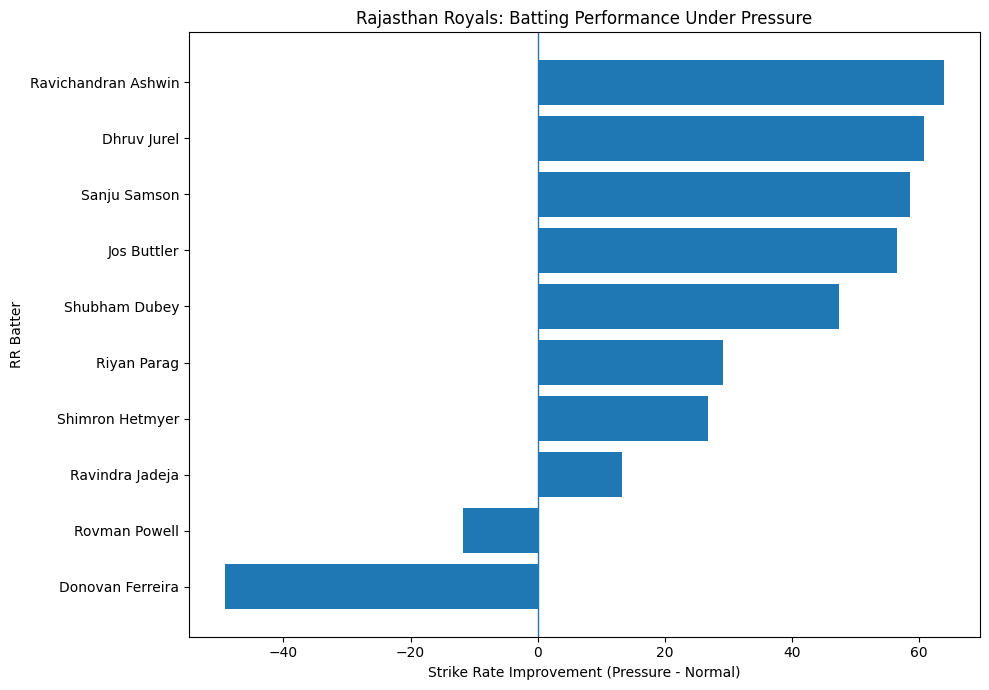

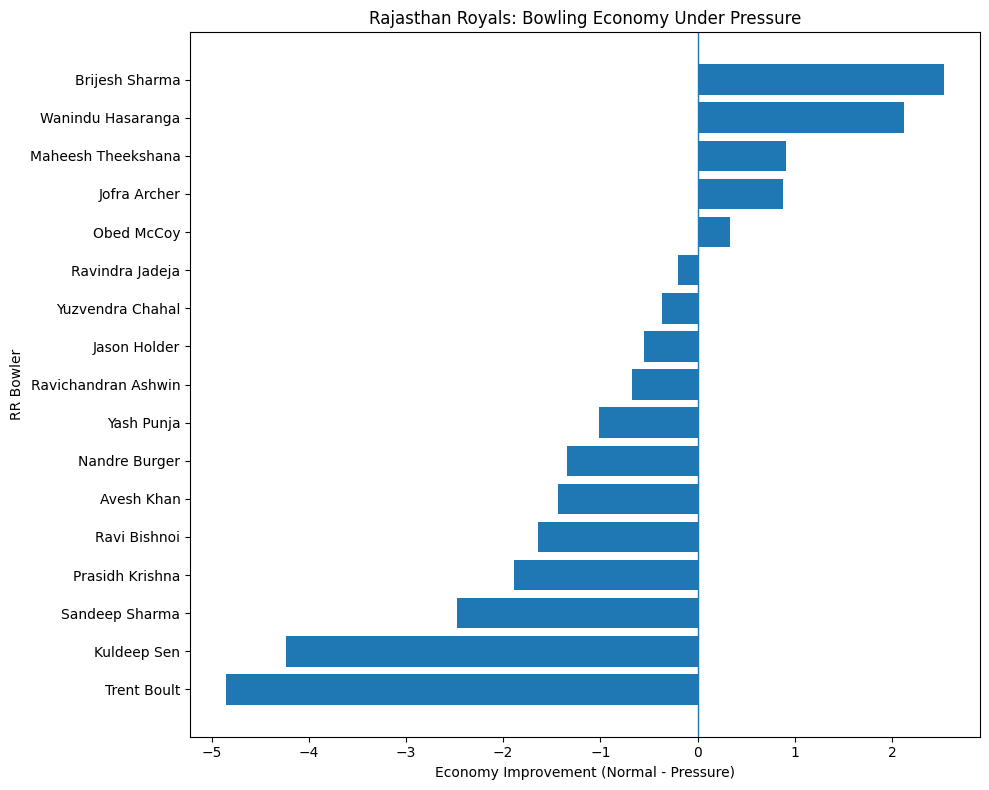

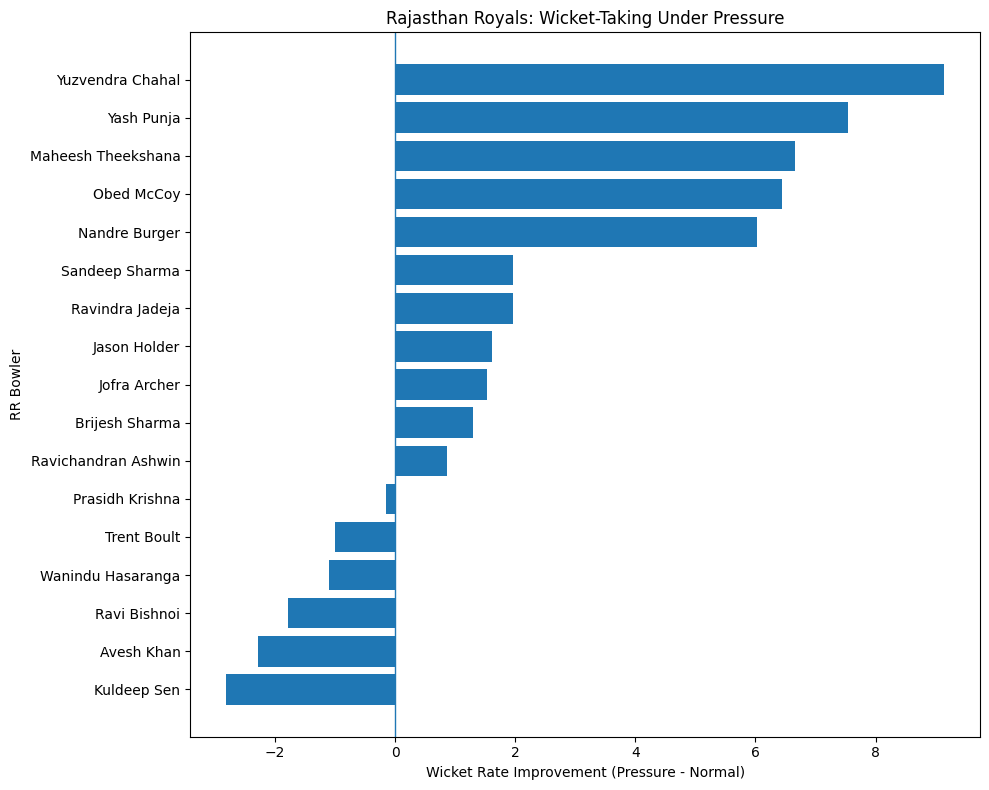

All RR charts saved successfully.


In [24]:

import os
import matplotlib.pyplot as plt

# Create output folder if it does not exist
os.makedirs("../outputs", exist_ok=True)

# ---------------------------------
# 1. EXPORT RR COMPARISON TABLES
# ---------------------------------

rr_batting_comparison.to_csv(
    "../outputs/rr_batting_pressure_comparison.csv",
    index=False
)

rr_bowling_comparison.to_csv(
    "../outputs/rr_bowling_pressure_comparison.csv",
    index=False
)

print("RR comparison CSV files saved successfully.")

# ---------------------------------
# 2. RR BATTING CHART
# ---------------------------------

batting_plot = rr_batting_comparison.dropna(
    subset=["sr_difference"]
).sort_values("sr_difference", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(
    batting_plot["striker_name"],
    batting_plot["sr_difference"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("Strike Rate Improvement (Pressure - Normal)")
plt.ylabel("RR Batter")
plt.title("Rajasthan Royals: Batting Performance Under Pressure")
plt.tight_layout()

plt.savefig(
    "../outputs/rr_batting_pressure_chart.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ---------------------------------
# 3. RR BOWLING ECONOMY CHART
# ---------------------------------

bowling_plot = rr_bowling_comparison.dropna(
    subset=["economy_improvement"]
).sort_values("economy_improvement", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(
    bowling_plot["bowler_name"],
    bowling_plot["economy_improvement"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("Economy Improvement (Normal - Pressure)")
plt.ylabel("RR Bowler")
plt.title("Rajasthan Royals: Bowling Economy Under Pressure")
plt.tight_layout()

plt.savefig(
    "../outputs/rr_bowling_economy_chart.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ---------------------------------
# 4. RR BOWLING WICKET-RATE CHART
# ---------------------------------

wicket_plot = rr_bowling_comparison.dropna(
    subset=["wicket_rate_improvement"]
).sort_values("wicket_rate_improvement", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(
    wicket_plot["bowler_name"],
    wicket_plot["wicket_rate_improvement"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("Wicket Rate Improvement (Pressure - Normal)")
plt.ylabel("RR Bowler")
plt.title("Rajasthan Royals: Wicket-Taking Under Pressure")
plt.tight_layout()

plt.savefig(
    "../outputs/rr_bowling_wicket_rate_chart.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("All RR charts saved successfully.")
